In [1]:
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Epoch 1/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 90s 234ms/step - accuracy: 0.3735 - loss: 1.8069 - val_accuracy: 0.6716 - val_loss: 0.9044 - learning_rate: 1.0000e-04
Epoch 2/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 80s 221ms/step - accuracy: 0.5433 - loss: 1.3319 - val_accuracy: 0.7008 - val_loss: 0.8257 - learning_rate: 1.0000e-04
Epoch 3/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 82s 228ms/step - accuracy: 0.5955 - loss: 1.1883 - val_accuracy: 0.7047 - val_loss: 0.8478 - learning_rate: 1.0000e-04
Epoch 4/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 80s 221ms/step - accuracy: 0.6179 - loss: 1.1079 - val_accuracy: 0.7464 - val_loss: 0.7082 - learning_rate: 1.0000e-04
Epoch 5/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 82s 227ms/step - accuracy: 0.6407 - loss: 1.0263 - val_accuracy: 0.7563 - val_loss: 0.6811 - learning_rate: 1.0000e-04
Epoch 6/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 80s 223ms/step -

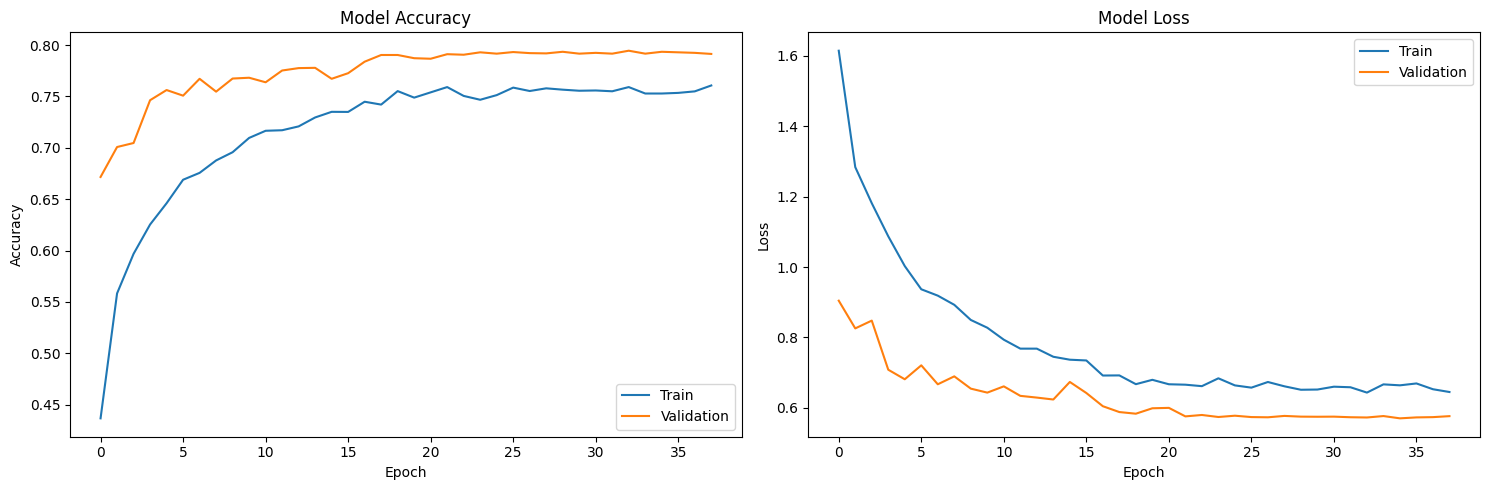

In [ ]:
# === 1. Setup ===
dataset_path = "../../../wheat_256px-dataset"
img_size = (256, 256)
batch_size = 32
num_classes = 5
seed = 42

# === 2. Load dataset with train/val/test split ===
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="training",
    seed=seed
)

val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="validation",
    seed=seed
)

val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

# === 3. Data Augmentation ===
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomZoom(0.2),
])

# === 4. Load pretrained InceptionV3 with proper preprocessing ===
base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(256, 256, 3)
)
base_model.trainable = False  # Freeze initially

# === 5. Build Model with Inception-specific adjustments ===
inputs = tf.keras.Input(shape=(256, 256, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.inception_v3.preprocess_input(x)  # Inception-specific preprocessing
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)  # Larger dense layer for Inception
x = Dropout(0.6)(x)  # Slightly higher dropout
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# === 6. Compile with adjusted learning rate ===
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === 7. Enhanced Callbacks ===
callbacks = [
    EarlyStopping(patience=5, monitor='val_accuracy', restore_best_weights=True),
    ModelCheckpoint('inceptionv3_best.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2)
]

# === 8. Training ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=60,  # Increased epochs
    callbacks=callbacks
)

# === 9. Evaluation ===
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\nTest accuracy: {test_acc:.2%}")

# === 10. Enhanced Visualization ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train')
ax1.plot(history.history['val_accuracy'], label='Validation')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

# Loss plot
ax2.plot(history.history['loss'], label='Train')
ax2.plot(history.history['val_loss'], label='Validation')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()